# VizWiz answerability: full pipeline (Project 2.2, individual)

**Vishnu Vardhan Manikandan**, Multimodal Data Fusion, Adelaide University, Semester 2 2026

One run reproduces every result in the report:

1. **Data and features** (`src/features.py`): downloads VizWiz-VQA (all three splits, with the labelled test annotations released in April 2026), measures photo quality, and extracts frozen ViT-B/16, BERT-base and CLIP ViT-B/32 features.
2. **Training** (`src/train.py`): question-only, image-only, late, early, cross-attention and gated fusion on ViT/BERT features, plus early and gated fusion on CLIP features, 3 seeds each; then the design ablation (`configs/ablation.yaml`).
3. **Evaluation** (`src/evaluate.py`): test metrics over seeds, bootstrap confidence intervals, McNemar tests, calibration, subgroups, gate analysis, modality ablation, latency, failure cases and data quality.

Settings live in `configs/`, and formats are described in `docs/data_contract.md`. Thresholds, the late-fusion weight and early stopping all use the development split (official validation); the test split is only scored.


## 1. Setup

In [1]:
REPO_URL = "https://github.com/vishnuvardhan0ffl/vizwiz-fusion-individual.git"  # @param {type:"string"}
RESULTS = "/content/drive/MyDrive/vizwiz_individual/results"

import os
from google.colab import drive
drive.mount("/content/drive")
REPO = "/content/" + REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")
if not os.path.exists(REPO):
    !git clone -q {REPO_URL} {REPO}
else:
    !git -C {REPO} pull -q
%cd {REPO}
!git log --oneline -1
!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader

Mounted at /content/drive
/content/vizwiz-fusion-individual
b00a07c (HEAD -> main, origin/main, origin/HEAD) Individual Project 2.2: features, training and evaluation pipeline
Tesla T4, 15360 MiB


In [2]:
# quick checks before the long run: training (synthetic data) and the full pipeline (stub encoders)
!python -m tests.test_smoke
!python -m tests.test_pipeline

{'train': 300, 'dev': 80, 'test': 100} pairs | device: cuda
[question_only seed 0] epoch  1  dev AUPRC 0.7998  (0.5s)
[question_only seed 0] epoch  2  dev AUPRC 0.9843  (0.0s)
[image_only seed 0] epoch  1  dev AUPRC 0.6480  (0.0s)
[image_only seed 0] epoch  2  dev AUPRC 0.9506  (0.0s)
[early seed 0] epoch  1  dev AUPRC 0.9444  (0.0s)
[early seed 0] epoch  2  dev AUPRC 1.0000  (0.0s)
[clip_early seed 0] epoch  1  dev AUPRC 0.8616  (0.0s)
[clip_early seed 0] epoch  2  dev AUPRC 0.9741  (0.0s)
[cross_attention seed 0] epoch  1  dev AUPRC 1.0000  (0.3s)
[cross_attention seed 0] epoch  2  dev AUPRC 1.0000  (0.0s)
[gated seed 0] epoch  1  dev AUPRC 0.9983  (0.1s)
[gated seed 0] epoch  2  dev AUPRC 1.0000  (0.0s)
[gated_clip seed 0] epoch  1  dev AUPRC 0.9968  (0.0s)
[gated_clip seed 0] epoch  2  dev AUPRC 0.9983  (0.0s)
[late seed 0] question weight 0.50  dev AUPRC 0.9983
[question_only seed 0] already has predictions, skipped
[image_only seed 0] already has predictions, skipped
[early seed 

## 2. Data and features

Downloads about 15 GB of photos, then extracts all features in one pass over the photos (about 20 minutes on a T4).

In [3]:
!python -m src.features --data-dir /content/data --out /content/features

Annotations.zip: 100% 1.71M/1.71M [00:00<00:00, 12.6MB/s]
train.zip: 100% 11.3G/11.3G [03:45<00:00, 50.0MB/s]
val.zip: 100% 3.49G/3.49G [01:20<00:00, 43.2MB/s]
test.zip: 100% 3.98G/3.98G [01:41<00:00, 39.4MB/s]
VQA_test.json: 100% 8.23M/8.23M [00:00<00:00, 37.5MB/s]
32,842 pairs with a photo (0 without); splits {'train': 20523, 'test': 8000, 'val': 4319}
preprocessor_config.json: 100% 160/160 [00:00<00:00, 721kB/s]
config.json: 100% 502/502 [00:00<00:00, 2.22MB/s]

model.safetensors: downloading bytes:  18% 63.2M/346M [00:01<00:03, 85.5MB/s, 3.34MB/s  ]
model.safetensors: downloading bytes:  40% 139M/346M [00:01<00:01, 167MB/s, 10.1MB/s  ] 
model.safetensors: downloading bytes:  54% 185M/346M [00:01<00:00, 188MB/s, 15.0MB/s  ]
model.safetensors: downloading bytes:  71% 246M/346M [00:01<00:00, 229MB/s, 20.3MB/s  ]
model.safetensors: reconstructing file:  31% 107M/346M [00:01<00:02, 83.5MB/s, 7.35MB/s  ] 
model.safetensors: downloading bytes:  86% 296M/346M [00:01<00:00, 234MB/s, 24.8MB/

## 3. Training

All models share one training loop and `configs/default.yaml`, 3 seeds each. The ablation varies modality dropout and cross-attention depth (`configs/ablation.yaml`).

In [4]:
!python -m src.train --config configs/default.yaml --model all --skip-existing

{'train': 20523, 'dev': 4319, 'test': 8000} pairs | device: cuda
[question_only seed 0] epoch  1  dev AUPRC 0.5528  (0.4s)
[question_only seed 0] epoch  2  dev AUPRC 0.5597  (0.2s)
[question_only seed 0] epoch  3  dev AUPRC 0.5653  (0.2s)
[question_only seed 0] epoch  4  dev AUPRC 0.5676  (0.2s)
[question_only seed 0] epoch  5  dev AUPRC 0.5675  (0.2s)
[question_only seed 0] epoch  6  dev AUPRC 0.5555  (0.2s)
[question_only seed 0] epoch  7  dev AUPRC 0.5530  (0.2s)
[question_only seed 0] epoch  8  dev AUPRC 0.5592  (0.2s)
[image_only seed 0] epoch  1  dev AUPRC 0.6060  (0.3s)
[image_only seed 0] epoch  2  dev AUPRC 0.6183  (0.2s)
[image_only seed 0] epoch  3  dev AUPRC 0.6201  (0.2s)
[image_only seed 0] epoch  4  dev AUPRC 0.6062  (0.2s)
[image_only seed 0] epoch  5  dev AUPRC 0.5999  (0.2s)
[image_only seed 0] epoch  6  dev AUPRC 0.6008  (0.2s)
[image_only seed 0] epoch  7  dev AUPRC 0.5971  (0.2s)
[early seed 0] epoch  1  dev AUPRC 0.7113  (0.3s)
[early seed 0] epoch  2  dev AUPRC 0

In [5]:
for m in ["gated_md0", "gated_md30", "gated_clip_md0", "cross_attention_l2"]:
    !python -m src.train --config configs/ablation.yaml --model {m} --skip-existing

{'train': 20523, 'dev': 4319, 'test': 8000} pairs | device: cuda
[gated_md0 seed 0] epoch  1  dev AUPRC 0.7152  (0.9s)
[gated_md0 seed 0] epoch  2  dev AUPRC 0.7176  (0.3s)
[gated_md0 seed 0] epoch  3  dev AUPRC 0.7302  (0.3s)
[gated_md0 seed 0] epoch  4  dev AUPRC 0.7148  (0.3s)
[gated_md0 seed 0] epoch  5  dev AUPRC 0.7073  (0.3s)
[gated_md0 seed 0] epoch  6  dev AUPRC 0.7227  (0.3s)
[gated_md0 seed 0] epoch  7  dev AUPRC 0.7069  (0.3s)
[gated_md0 seed 1] epoch  1  dev AUPRC 0.7076  (0.3s)
[gated_md0 seed 1] epoch  2  dev AUPRC 0.7230  (0.3s)
[gated_md0 seed 1] epoch  3  dev AUPRC 0.7329  (0.3s)
[gated_md0 seed 1] epoch  4  dev AUPRC 0.7248  (0.3s)
[gated_md0 seed 1] epoch  5  dev AUPRC 0.7103  (0.3s)
[gated_md0 seed 1] epoch  6  dev AUPRC 0.7111  (0.3s)
[gated_md0 seed 1] epoch  7  dev AUPRC 0.6888  (0.3s)
[gated_md0 seed 2] epoch  1  dev AUPRC 0.7107  (0.3s)
[gated_md0 seed 2] epoch  2  dev AUPRC 0.7240  (0.3s)
[gated_md0 seed 2] epoch  3  dev AUPRC 0.7298  (0.3s)
[gated_md0 seed 2

## 4. Evaluation

In [6]:
!python -m src.evaluate --config configs/default.yaml --ablation-config configs/ablation.yaml --out {RESULTS}

Loading weights: 100% 200/200 [00:00<00:00, 858.10it/s]
Loading weights: 100% 199/199 [00:00<00:00, 872.18it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100% 398/398 [00:00<00:00, 26860.17it/s]

=== Test results (mean +/- std over seeds) ===
                   macro_f1         auprc 

data_quality


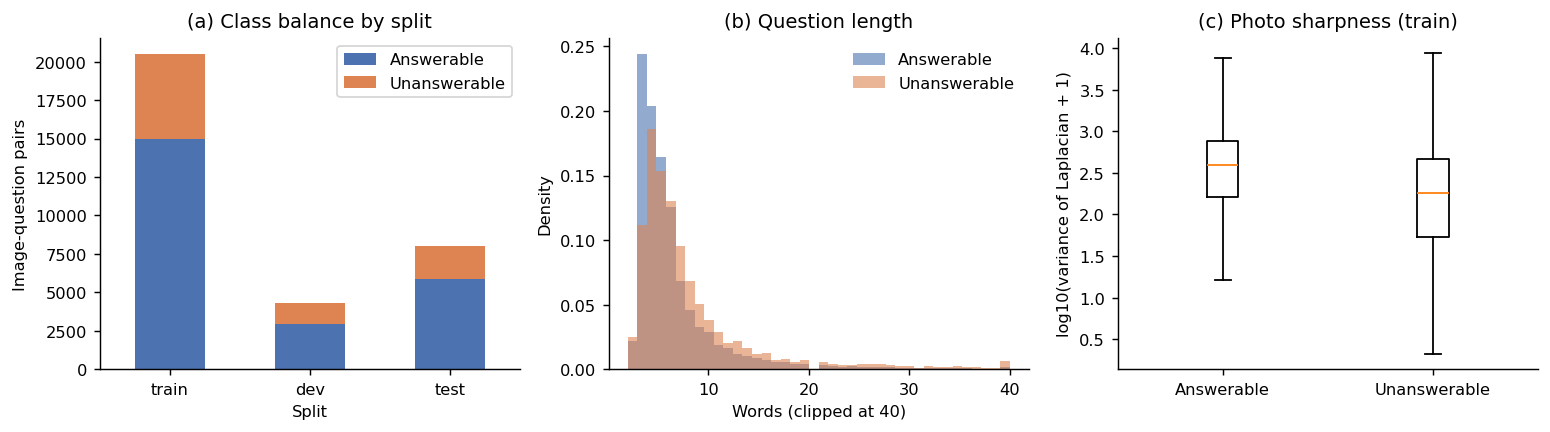

model_comparison


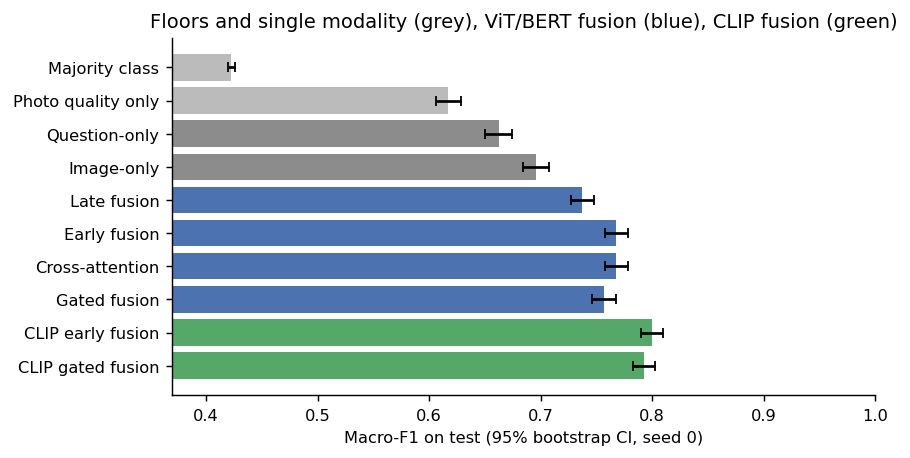

roc_pr_calibration


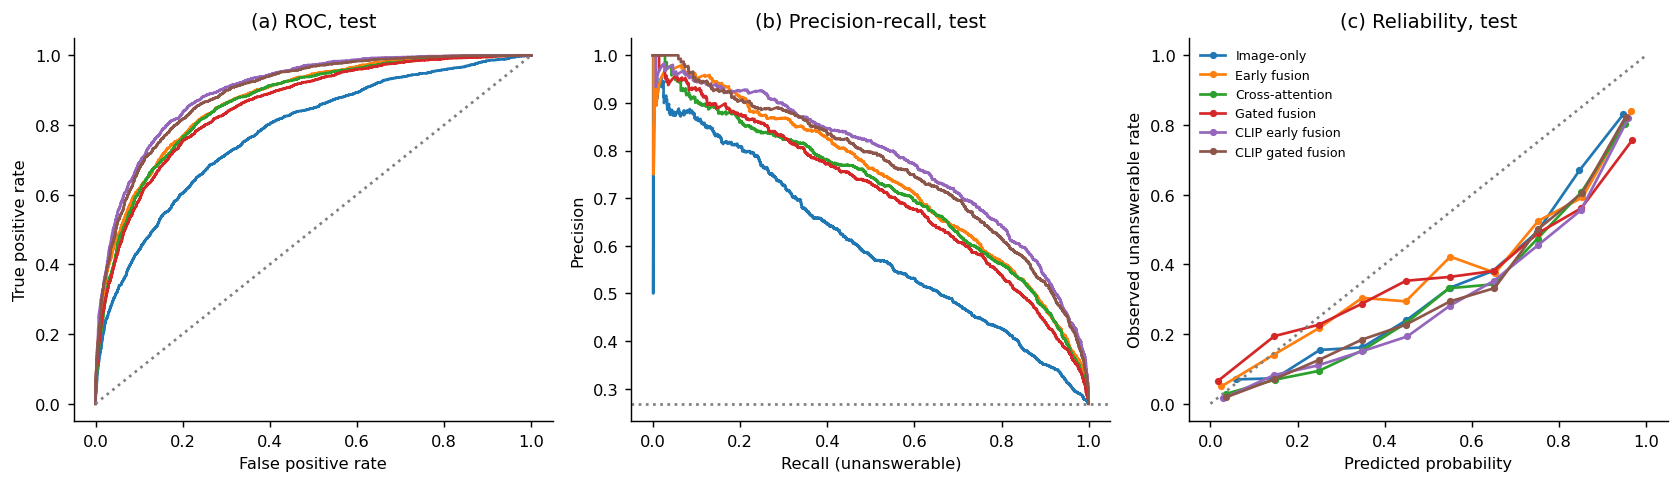

subgroups_sharpness


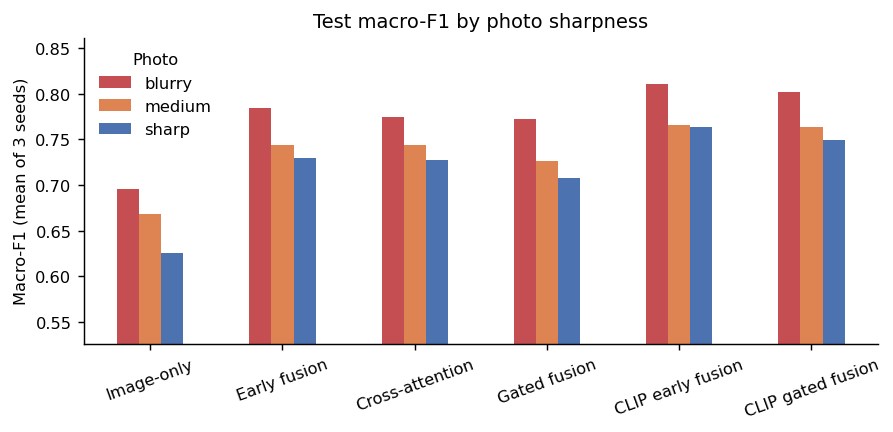

learning_curves


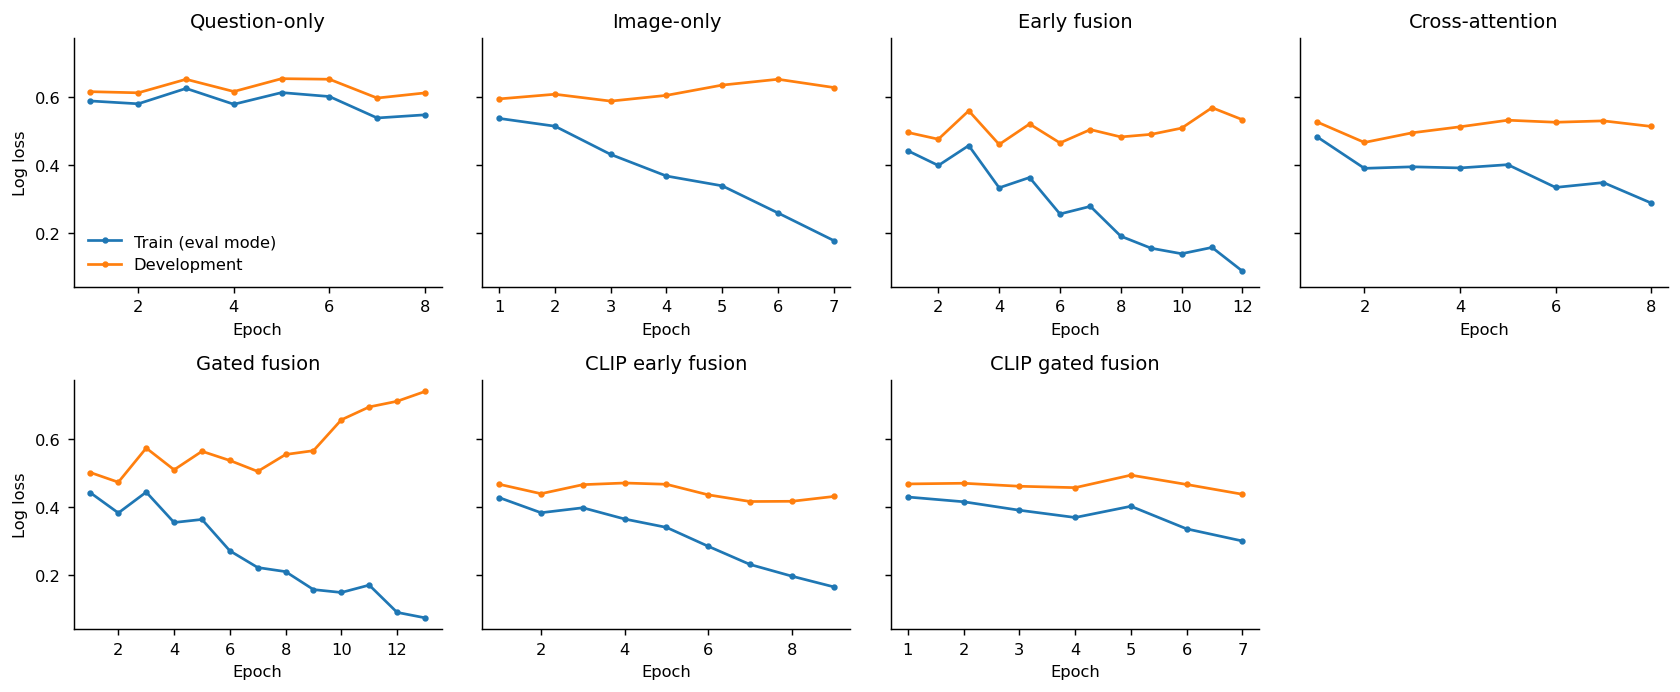

modality_ablation


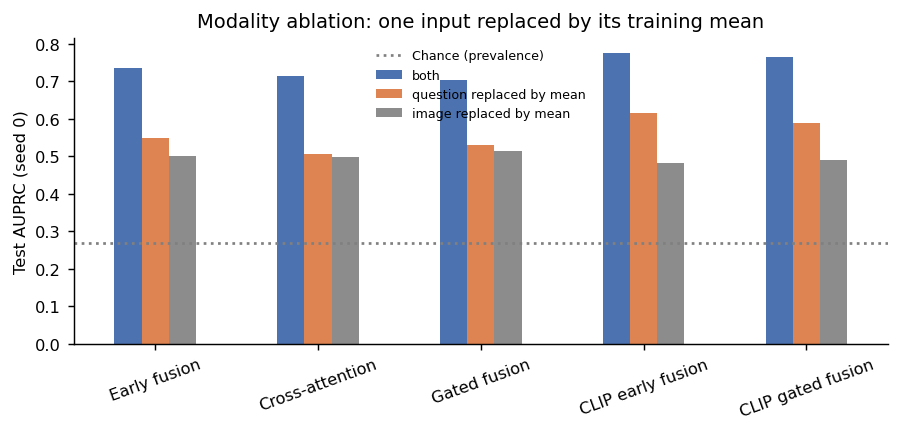

failure_cases


(failure_cases.png is not shown in the repository because it contains VizWiz photos; see Figure 3 of the report)


In [7]:
from IPython.display import Image, display
for name in ["data_quality", "model_comparison", "roc_pr_calibration", "subgroups_sharpness",
             "learning_curves", "modality_ablation", "failure_cases"]:
    path = f"{RESULTS}/figures/{name}.png"
    if os.path.exists(path):
        print(name)
        display(Image(path))

In [8]:
!python scripts/config_table.py --out {RESULTS}/tables/appendix_a_configs.csv

          set              model           class features                                       settings  params  seeds  epochs  sec_per_epoch  peak_vram_gb  dev_auprc_mean  dev_auprc_std
         runs         clip_early           early     clip                        hidden=256, dropout=0.3  264705      3    10.0           0.21         0.037           0.796          0.005
         runs    cross_attention cross_attention vit_bert    d_model=256, heads=4, layers=1, dropout=0.1  987905      3     7.7           4.13         0.778           0.742          0.003
         runs              early           early vit_bert                        hidden=256, dropout=0.3  396801      3    10.7           0.24         0.047           0.743          0.003
         runs              gated           gated vit_bert hidden=256, dropout=0.3, modality_dropout=0.15  853761      3     9.3           0.31         0.050           0.725          0.003
         runs         gated_clip           gated     clip hi

## References

Brier, GW 1950, 'Verification of forecasts expressed in terms of probability', *Monthly Weather Review*, vol. 78, no. 1, pp. 1-3.

Devlin, J, Chang, M-W, Lee, K & Toutanova, K 2019, 'BERT: pre-training of deep bidirectional transformers for language understanding', in *Proceedings of the 2019 conference of the North American chapter of the Association for Computational Linguistics: human language technologies*, vol. 1, Association for Computational Linguistics, Minneapolis, USA, pp. 4171-4186.

Dietterich, TG 1998, 'Approximate statistical tests for comparing supervised classification learning algorithms', *Neural Computation*, vol. 10, no. 7, pp. 1895-1923.

Dosovitskiy, A, Beyer, L, Kolesnikov, A, Weissenborn, D, Zhai, X, Unterthiner, T, Dehghani, M, Minderer, M, Heigold, G, Gelly, S, Uszkoreit, J & Houlsby, N 2021, 'An image is worth 16x16 words: transformers for image recognition at scale', in *International conference on learning representations (ICLR 2021)*, online.

Efron, B & Tibshirani, RJ 1993, *An introduction to the bootstrap*, Chapman & Hall, New York.

Gurari, D, Li, Q, Stangl, AJ, Guo, A, Lin, C, Grauman, K, Luo, J & Bigham, JP 2018, 'VizWiz grand challenge: answering visual questions from blind people', in *Proceedings of the IEEE conference on computer vision and pattern recognition (CVPR)*, IEEE, Salt Lake City, USA, pp. 3608-3617.

Guo, C, Pleiss, G, Sun, Y & Weinberger, KQ 2017, 'On calibration of modern neural networks', in *Proceedings of the 34th international conference on machine learning*, PMLR, vol. 70, pp. 1321-1330.

Holm, S 1979, 'A simple sequentially rejective multiple test procedure', *Scandinavian Journal of Statistics*, vol. 6, no. 2, pp. 65-70.

Mann, HB & Whitney, DR 1947, 'On a test of whether one of two random variables is stochastically larger than the other', *Annals of Mathematical Statistics*, vol. 18, no. 1, pp. 50-60.

McNemar, Q 1947, 'Note on the sampling error of the difference between correlated proportions or percentages', *Psychometrika*, vol. 12, no. 2, pp. 153-157.

Pech-Pacheco, JL, Cristobal, G, Chamorro-Martinez, J & Fernandez-Valdivia, J 2000, 'Diatom autofocusing in brightfield microscopy: a comparative study', in *Proceedings of the 15th international conference on pattern recognition (ICPR 2000)*, vol. 3, IEEE, Barcelona, Spain, pp. 314-317.

Radford, A, Kim, JW, Hallacy, C, Ramesh, A, Goh, G, Agarwal, S, Sastry, G, Askell, A, Mishkin, P, Clark, J, Krueger, G & Sutskever, I 2021, 'Learning transferable visual models from natural language supervision', in *Proceedings of the 38th international conference on machine learning (ICML 2021)*, PMLR, vol. 139, pp. 8748-8763.

Saito, T & Rehmsmeier, M 2015, 'The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets', *PLoS ONE*, vol. 10, no. 3, article no. e0118432.

VizWiz n.d., *Visual question answering*, VizWiz, viewed 20 October 2026, <https://vizwiz.org/tasks-and-datasets/vqa/>.

Wolf, T, Debut, L, Sanh, V, Chaumond, J, Delangue, C, Moi, A, Cistac, P, Rault, T, Louf, R, Funtowicz, M, Davison, J, Shleifer, S, von Platen, P, Ma, C, Jernite, Y, Plu, J, Xu, C, Le Scao, T, Gugger, S, Drame, M, Lhoest, Q & Rush, AM 2020, 'Transformers: state-of-the-art natural language processing', in *Proceedings of the 2020 conference on empirical methods in natural language processing: system demonstrations*, Association for Computational Linguistics, online, pp. 38-45.